# Steam EDA

Goal: the facts the **Exploratory Analysis** section needs, and the ones that justify
our modeling and evaluation choices (ranking with leave-one-out, popularity baseline,
`1 + log1p(playtime)` target, uniform negatives).

Each section: the question, why it matters for the write-up, and hints. Keep cells
short; anything reusable moves into `src/`. Save figures you want in the slides to
`cfg.paths.figures`.

In [41]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

from assignment_2.modules.config import get_config
from assignment_2.modules.core import top_share
from assignment_2.modules.core.plots import log_hist, save, use_style
from assignment_2.modules.data import load_prepped, read_meta


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [42]:
# Style plots
use_style()

In [43]:
cfg = get_config()
print(f"sample={cfg.sample.tag}  seed={cfg.seed}  split={cfg.split.holdout}/{cfg.split.n_holdout}")
print(f"dataset={cfg.dataset}  sample={cfg.sample.tag}  seed={cfg.seed}")

t = load_prepped(cfg)
meta = read_meta(cfg)
train = t["interactions_train"]
owned = pd.concat([t[f"interactions_{s}"] for s in ("train", "valid", "test")], ignore_index=True)
items, bundles = t["items"], t["bundles"]
reviews = pd.concat([t[f"reviews_{s}"] for s in ("train", "valid", "test")], ignore_index=True)
sorted(t)

sample=users_0.1  seed=258  split=count/1
dataset=steam  sample=users_0.1  seed=258


['bundles',
 'interactions_test',
 'interactions_test_candidates',
 'interactions_train',
 'interactions_valid',
 'interactions_valid_candidates',
 'items',
 'reviews_test',
 'reviews_train',
 'reviews_valid']

## 1. Dataset summary
The first slide of the EDA section. Built from `meta.json`, so it matches exactly
what `prep` produced.

In [44]:
s = meta["stats"]
rows = {
    "users": s["interactions"]["all"]["users"],
    "games (owned by anyone)": s["interactions"]["all"]["items"],
    "ownership rows": s["interactions"]["all"]["rows"],
    "sparsity": round(s["interactions"]["all"]["sparsity"], 4),
    "train / valid / test rows": "{:,} / {:,} / {:,}".format(
        *(s["interactions"][k]["rows"] for k in ("train", "valid", "test"))
    ),
    "cold held-out rows dropped": s["interactions"]["cold_dropped"],
    "games with metadata": s["items"]["rows"],
    "reviews": s["reviews"]["all"]["rows"],
    "reviews with no year": f"{s['reviews']['undated_share']:.1%}",
    "bundles": s["bundles"]["bundles"],
}
pd.Series(rows, name=cfg.sample.tag).to_frame()

,users_0.1
users,7058
games (owned by anyone),8372
ownership rows,490861
sparsity,0.9917
train / valid / test rows,"477,777 / 6,535 / 6,534"
cold held-out rows dropped,15
games with metadata,32132
reviews,5954
reviews with no year,16.5%
bundles,615


## 2. How concentrated is ownership? (the long tail)
**Why:** if a few games account for most ownership, popularity is a strong baseline,
and that's the bar every model has to clear. It also explains why sampled negatives
are mostly obscure games.

**Do:**
- games per user: `owned.groupby("user_id").size()`; describe() + histogram (log x).
- owners per game: `owned.item_id.value_counts()`; plot rank vs count on log-log axes.
- share of all ownership rows covered by the top 1% / 10% of games
  (sort counts descending, `cumsum() / total`).

**Write-up line:** "The top X% of games account for Y% of ownership."

In [45]:
games_per_user = owned.groupby('user_id').size()
games_per_user.describe()

count    7058.000000
mean       69.544630
std       110.133313
min         1.000000
25%        14.000000
50%        40.000000
75%        86.000000
max      3730.000000
dtype: float64

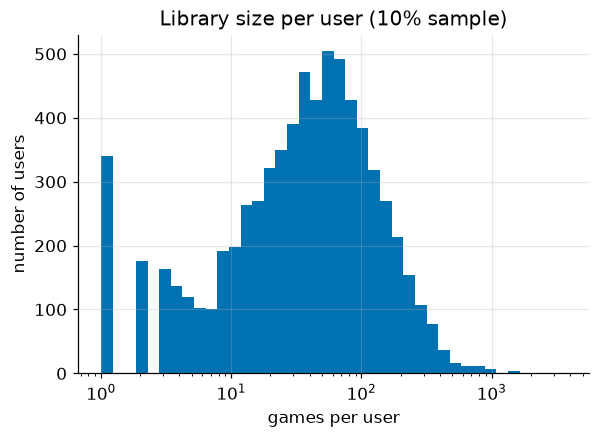

In [46]:
fig, ax = plt.subplots(figsize=(6, 4))   # a figure and one set of axes
log_hist(ax, games_per_user, "games per user", "number of users", "Library size per user (10% sample)")
path = save(fig, "games_per_user")

plt.show()

In [47]:
owners_per_game = owned['item_id'].value_counts()
owners_per_game.describe()


count    8357.000000
mean       58.734713
std       201.420084
min         1.000000
25%         2.000000
50%         8.000000
75%        32.000000
max      4905.000000
Name: count, dtype: float64

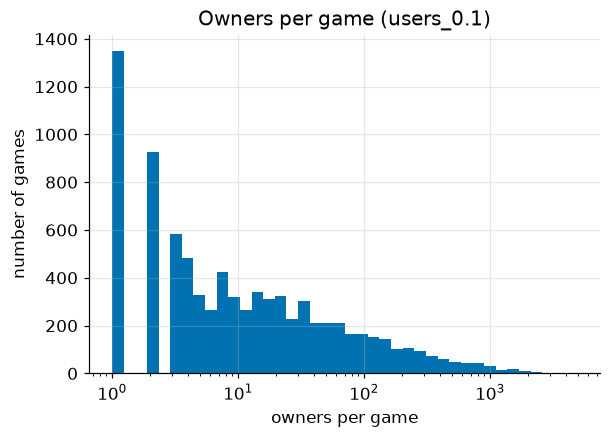

In [48]:
fig, ax = plt.subplots()
log_hist(ax, owners_per_game, "owners per game", "number of games", f"Owners per game ({cfg.sample.tag})")
save(fig, "owners_per_game")
plt.show()

In [49]:
assert top_share(pd.Series([50, 30, 10, 5, 5]), 0.4) == 0.8   # top 2 of 5 games

for frac in (0.01, 0.10, 0.50):
    print(f"top {frac:.0%} of games: {top_share(owners_per_game, frac):.1%} of ownership")

top 1% of games: 26.7% of ownership
top 10% of games: 74.1% of ownership
top 50% of games: 97.6% of ownership


## 3. Playtime: is "owned" the same as "played"?
**Why:** justifies the training target. If many owned games have 0 minutes, ownership
alone is a weak signal; that's why owned rows get `1 + log1p(playtime)`, so
owned-but-unplayed (target 1) stays above not-owned (0).

**Do:**
- share of ownership rows with `playtime_forever == 0`.
- histogram of `np.log1p(playtime_forever)` for played rows (raw playtime is far too
  skewed to plot directly; note the units are minutes).
- per user: share of their library never played. Is it a few users or everyone?

In [50]:
played = owned.playtime_forever > 0
stats = pd.Series({
    "ownership rows": f"{len(owned):,}",
    "never played (lifetime)": f"{(~played).mean():.1%}",
    "not played in last 2 weeks": f"{(owned.playtime_2weeks == 0).mean():.1%}",
}, name="value")
stats.to_frame()

,value
ownership rows,"490,846"
never played (lifetime),35.9%
not played in last 2 weeks,97.3%


36% of owned games have never been played, so ownership alone is a noisy signal of preference.

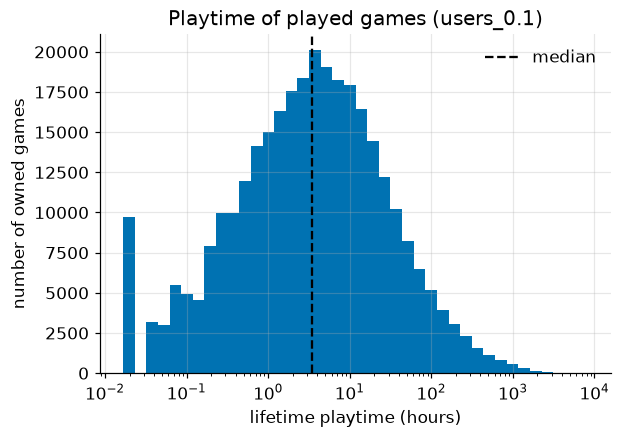

Median playtime of played games: 3.5 hours


In [51]:
played_hours = owned.loc[played, "playtime_forever"] / 60

fig, ax = plt.subplots()
log_hist(ax, played_hours, "lifetime playtime (hours)", "number of owned games",
         f"Playtime of played games ({cfg.sample.tag})")
ax.axvline(played_hours.median(), linestyle="--", color="black", label="median")
ax.legend()
save(fig, "playtime_played")
plt.show()

print(f"Median playtime of played games: {played_hours.median():.1f} hours")

In [52]:
for cutoff in (1, 5, 30, 120):                       # minutes
    share = (owned.playtime_forever < cutoff).mean()   # share of ALL owned rows with playtime_forever < cutoff
    print(f"< {cutoff:>3} min: {share:.1%} of owned games")

<   1 min: 35.9% of owned games
<   5 min: 39.7% of owned games
<  30 min: 48.6% of owned games
< 120 min: 61.6% of owned games


In [53]:
for frac in (0.01, 0.10, 0.50):
    share = top_share(played_hours, frac)
    print(f"top {frac:.0%} of played (user, game) pairs: {share:.1%} of all hours played")

top 1% of played (user, game) pairs: 33.5% of all hours played
top 10% of played (user, game) pairs: 76.6% of all hours played
top 50% of played (user, game) pairs: 98.0% of all hours played


Playtime is extremely skewed: 1% of played (user, game) pairs account for 33% of all hours. We therefore model log(1 + minutes) rather than raw playtime, which makes the distribution roughly symmetric (see histogram).

## 4. Do popular games get played more?
**Why:** if popularity and playtime are strongly related, the playtime target mostly
re-encodes popularity; if not, it adds signal beyond it (experiment 2 vs 1 in the plan).

**Do:** per game, number of owners vs median `log1p(playtime)` among owners (scatter,
log x). Report a rank correlation (`scipy.stats.spearmanr`).

In [54]:
owned = owned.assign(log_playtime=np.log1p(owned.playtime_forever))

per_game = owned.groupby("item_id").agg(
    owners=("user_id", "size"),
    median_log_playtime=("log_playtime", "median"),
    median_hours=("playtime_forever", lambda s: s.median() / 60),
)
per_game.describe()

,owners,median_log_playtime,median_hours
count,8357.000000,8357.000000,8357.000000
mean,58.734713,1.958206,1.792813
std,201.420084,2.228862,14.051862
min,1.000000,0.000000,0.000000
25%,2.000000,0.000000,0.000000
50%,8.000000,0.804719,0.025000
75%,32.000000,3.871201,1.033333
max,4905.000000,10.910953,912.866667


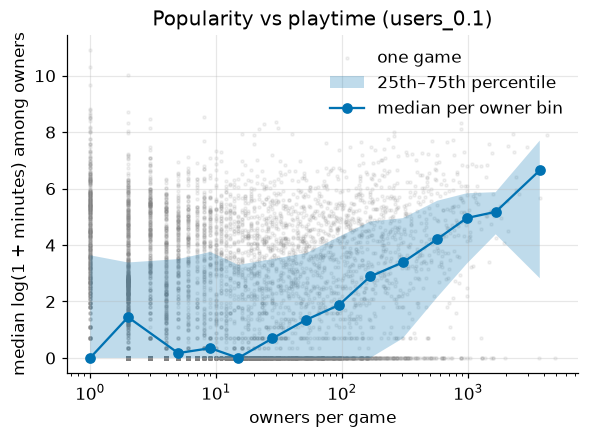

Spearman ρ = 0.19 across 5,013 games with ≥ 5 owners


,owners,mid,lo,hi,n_games
bin,,,,,
"(0.999, 1.835]",1.0,0.00,0.00,3.64,1350
"(1.835, 3.367]",2.0,1.45,0.00,3.38,1511
"(3.367, 6.178]",5.0,0.17,0.00,3.50,1074
"(6.178, 11.336]",9.0,0.35,0.00,3.75,881
"(11.336, 20.801]",15.0,0.00,0.00,3.30,860
"(20.801, 38.168]",28.0,0.69,0.00,3.50,810
"(38.168, 70.036]",52.0,1.35,0.00,3.71,595
"(70.036, 128.51]",94.0,1.87,0.00,4.29,463
"(128.51, 235.805]",167.5,2.89,0.00,4.83,344


In [55]:
MIN_OWNERS = 5  # games with fewer owners have a "median" of 1-4 people; too noisy to read

edges = np.geomspace(1, per_game.owners.max(), 15)
binned = (
    per_game.assign(bin=pd.cut(per_game.owners, bins=edges, include_lowest=True))
    .groupby("bin", observed=True)
    .agg(
        owners=("owners", "median"),
        mid=("median_log_playtime", "median"),
        lo=("median_log_playtime", lambda s: s.quantile(0.25)),
        hi=("median_log_playtime", lambda s: s.quantile(0.75)),
        n_games=("owners", "size"),
    )
)

fig, ax = plt.subplots()
ax.scatter(per_game.owners, per_game.median_log_playtime, s=4, alpha=0.1, color="gray", label="one game")
ax.fill_between(binned.owners, binned.lo, binned.hi, alpha=0.25, label="25th–75th percentile")
ax.plot(binned.owners, binned.mid, marker="o", label="median per owner bin")
ax.set(xscale="log", xlabel="owners per game", ylabel="median log(1 + minutes) among owners",
       title=f"Popularity vs playtime ({cfg.sample.tag})")
ax.legend()
save(fig, "popularity_vs_playtime")
plt.show()

frequent = per_game[per_game.owners >= MIN_OWNERS]
rho, p = spearmanr(frequent.owners, frequent.median_log_playtime)
print(f"Spearman ρ = {rho:.2f} across {len(frequent):,} games with ≥ {MIN_OWNERS} owners")
binned.round(2)

how many owners open the game at all, and how much those who open it play

In [56]:
per_game = owned.groupby("item_id").agg(
    owners=("user_id", "size"),
    median_log_playtime=("log_playtime", "median"),
    median_hours=("playtime_forever", lambda s: s.median() / 60),
    play_rate=("playtime_forever", lambda s: (s > 0).mean()),
    played_median_log=("log_playtime", lambda s: s[s > 0].median()),
)
per_game.describe()

,owners,median_log_playtime,median_hours,play_rate,played_median_log
count,8357.000000,8357.000000,8357.000000,8357.000000,6697.000000
mean,58.734713,1.958206,1.792813,0.483640,4.284584
std,201.420084,2.228862,14.051862,0.348825,1.476725
min,1.000000,0.000000,0.000000,0.000000,0.693147
25%,2.000000,0.000000,0.000000,0.166667,3.312696
50%,8.000000,0.804719,0.025000,0.500000,4.442651
75%,32.000000,3.871201,1.033333,0.775000,5.323010
max,4905.000000,10.910953,912.866667,1.000000,11.209764


In [57]:
f = per_game[per_game.owners >= MIN_OWNERS]
for col in ("play_rate", "played_median_log"):
    rho, _ = spearmanr(f.owners, f[col], nan_policy="omit")
    print(f"owners vs {col}: ρ = {rho:.2f}")

owners vs play_rate: ρ = 0.20
owners vs played_median_log: ρ = 0.13


Engagement is largely independent of popularity: across games with ≥ 5 owners, the share of owners who ever play a game (ρ = 0.20) and how long players play it (ρ = 0.13) are only weakly correlated with its number of owners. 20% of games were never opened by any owner, and for the typical game only half its owners played it.

## 5. Metadata and bundle coverage
**Why:** genre/tag and bundle features only help games that have them. Coverage
decides whether they're worth building.

**Do:**
- share of owned games (and of ownership *rows*) whose `item_id` is in `items`.
  Rows matter more: popular games dominate rows.
- most common genres among owned games: `items.explode("genres")`, joined to ownership.
- share of owned games that appear in any bundle.

In [58]:
# TODO: metadata coverage (games and rows), top genres, bundle coverage

## 6. Reviews
**Why:** context for the dataset section, and the only data with timestamps.

**Do:**
- share of reviews with `recommend == True`.
- reviews per year (`posted.dt.year.value_counts()`), plus the undated share.
- how many reviewers also appear in the ownership data?

In [59]:
# TODO: recommend rate, reviews per year, overlap with owners

## 7. Evaluation sanity checks
**Why:** confirms the protocol before any model is trusted, and gives the numbers the
Evaluation section cites.

**Do:**
- candidates: positives per user (should be exactly 1 with leave-one-out) and list
  size per user (should be 100).
- popularity gap: mean train popularity of positives vs negatives in
  `interactions_valid_candidates`. A large gap means uniform negatives are easy, so
  popularity will score well; this motivates also reporting popularity-weighted
  negatives.
- random scores: Hit@10 should be ~0.10. Use `ranking_per_user` from
  `assignment_2.modules.core.metrics` with `np.random.default_rng(0).random(len(c))`.
- popularity scores (train owner counts mapped onto candidates): Hit@10 / NDCG@10 is
  the first baseline row of the results table.

In [60]:
c = t["interactions_valid_candidates"]
# TODO: positives and list size per user

In [61]:
# TODO: popularity of positives vs negatives

In [62]:
# TODO: random-score and popularity-score Hit@10 / NDCG@10

## Takeaways (fill in as you go)
- Long tail:
- Playtime:
- Popularity vs playtime:
- Metadata / bundle coverage:
- Evaluation checks: